# Task 1 - Student Score Prediction
**Elevvo ML Internship - Level 1**

Goal: predict a student's exam score from study hours using linear regression, then compare against polynomial regression and other feature combinations.

Dataset: [Student Performance Factors (Kaggle)](https://www.kaggle.com/datasets/lainguyn123/student-performance-factors) - put `StudentPerformanceFactors.csv` in the same folder as this notebook (in Colab, upload it with the Files panel).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

### Terminal-style output
`rich` draws the results as boxed terminal tables, and the charts use a matching dark monospace theme.

In [2]:
from rich.console import Console
from rich.table import Table
from rich.panel import Panel
from rich import box

console = Console()
GREEN, CYAN, AMBER = '#33ff66', '#00e5ff', '#ffb000'

plt.style.use('dark_background')
plt.rcParams.update({
    'font.family': 'monospace', 'axes.edgecolor': GREEN, 'axes.labelcolor': GREEN,
    'xtick.color': GREEN, 'ytick.color': GREEN, 'axes.titlecolor': GREEN,
    'axes.grid': True, 'grid.color': '#1f3d1f', 'grid.linestyle': ':',
})

def term_table(df, title, index=True):
    t = Table(title=f'> {title}', title_justify='left', title_style=f'bold {GREEN}',
              box=box.SQUARE, border_style=GREEN, header_style=f'bold {CYAN}')
    if index:
        t.add_column(str(df.index.name or ''), style=AMBER)
    for col in df.columns:
        t.add_column(str(col), justify='right', style=GREEN)
    for idx, *row in df.itertuples():
        values = [f'{v:,.3f}' if isinstance(v, float) else str(v) for v in row]
        t.add_row(*([str(idx)] if index else []), *values)
    console.print(t)

def term_panel(title, lines):
    body = '\n'.join(f'[{GREEN}]$[/] {line}' for line in lines)
    console.print(Panel(body, title=f'[bold {GREEN}]{title}', title_align='left',
                        border_style=GREEN, box=box.SQUARE, expand=False))

## 1. Load and explore the data

In [3]:
df = pd.read_csv('StudentPerformanceFactors.csv')
term_panel('DATASET LOADED', [f'rows    : {df.shape[0]:,}', f'columns : {df.shape[1]}'])
term_table(df.head(3).T.rename(columns=lambda i: f'student {i}'), 'FIRST 3 STUDENTS')

┌─ DATASET LOADED ──┐
│ $ rows    : 6,607 │
│ $ columns : 20    │
└───────────────────┘

> FIRST 3 STUDENTS                                                     
┌────────────────────────────┬─────────────┬───────────┬──────────────┐
│                            │   student 0 │ student 1 │    student 2 │
├────────────────────────────┼─────────────┼───────────┼──────────────┤
│ Hours_Studied              │          23 │        19 │           24 │
│ Attendance                 │          84 │        64 │           98 │
│ Parental_Involvement       │         Low │       Low │       Medium │
│ Access_to_Resources        │        High │    Medium │       Medium │
│ Extracurricular_Activities │          No │        No │          Yes │
│ Sleep_Hours                │           7 │         8 │            7 │
│ Previous_Scores            │          73 │        59 │           91 │
│ Motivation_Level           │         Low │       Low │       Medium │
│ Internet_Access            │         Yes │       Yes │          Yes │
│ Tutoring_Sessions          │           0 │         2 │            2 │
│ Family_Income              │         Low │    Medium │       Medium │
│ Teacher_Quality            │      Medium │    Medium │       Medium │
│ School_Type                │      Public │    Public │       Public │
│ Peer_Influence             │    Positive │  Negative │      Neutral │
│ Physical_Activity          │           3 │         4 │            4 │
│ Learning_Disabilities      │          No │        No │           No │
│ Parental_Education_Level   │ High School │   College │ Postgraduate │
│ Distance_from_Home         │        Near │  Moderate │         Near │
│ Gender                     │        Male │    Female │         Male │
│ Exam_Score                 │          67 │        61 │           74 │
└────────────────────────────┴─────────────┴───────────┴──────────────┘

In [4]:
info = pd.DataFrame({'dtype': df.dtypes.astype(str), 'non_null': df.notnull().sum(), 'missing': df.isnull().sum()})
term_table(info, 'COLUMN INFO')

> COLUMN INFO                                              
┌────────────────────────────┬───────┬──────────┬─────────┐
│                            │ dtype │ non_null │ missing │
├────────────────────────────┼───────┼──────────┼─────────┤
│ Hours_Studied              │ int64 │     6607 │       0 │
│ Attendance                 │ int64 │     6607 │       0 │
│ Parental_Involvement       │   str │     6607 │       0 │
│ Access_to_Resources        │   str │     6607 │       0 │
│ Extracurricular_Activities │   str │     6607 │       0 │
│ Sleep_Hours                │ int64 │     6607 │       0 │
│ Previous_Scores            │ int64 │     6607 │       0 │
│ Motivation_Level           │   str │     6607 │       0 │
│ Internet_Access            │   str │     6607 │       0 │
│ Tutoring_Sessions          │ int64 │     6607 │       0 │
│ Family_Income              │   str │     6607 │       0 │
│ Teacher_Quality            │   str │     6529 │      78 │
│ School_Type                │   str │     6607 │       0 │
│ Peer_Influence             │   str │     6607 │       0 │
│ Physical_Activity          │ int64 │     6607 │       0 │
│ Learning_Disabilities      │   str │     6607 │       0 │
│ Parental_Education_Level   │   str │     6517 │      90 │
│ Distance_from_Home         │   str │     6540 │      67 │
│ Gender                     │   str │     6607 │       0 │
│ Exam_Score                 │ int64 │     6607 │       0 │
└────────────────────────────┴───────┴──────────┴─────────┘

In [5]:
term_table(df.describe().T.round(2), 'NUMERIC SUMMARY')

> NUMERIC SUMMARY                                                                                
┌───────────────────┬───────────┬────────┬────────┬────────┬────────┬────────┬────────┬─────────┐
│                   │     count │   mean │    std │    min │    25% │    50% │    75% │     max │
├───────────────────┼───────────┼────────┼────────┼────────┼────────┼────────┼────────┼─────────┤
│ Hours_Studied     │ 6,607.000 │ 19.980 │  5.990 │  1.000 │ 16.000 │ 20.000 │ 24.000 │  44.000 │
│ Attendance        │ 6,607.000 │ 79.980 │ 11.550 │ 60.000 │ 70.000 │ 80.000 │ 90.000 │ 100.000 │
│ Sleep_Hours       │ 6,607.000 │  7.030 │  1.470 │  4.000 │  6.000 │  7.000 │  8.000 │  10.000 │
│ Previous_Scores   │ 6,607.000 │ 75.070 │ 14.400 │ 50.000 │ 63.000 │ 75.000 │ 88.000 │ 100.000 │
│ Tutoring_Sessions │ 6,607.000 │  1.490 │  1.230 │  0.000 │  1.000 │  1.000 │  2.000 │   8.000 │
│ Physical_Activity │ 6,607.000 │  2.970 │  1.030 │  0.000 │  2.000 │  3.000 │  4.000 │   6.000 │
│ Exam_Score        │ 6,607.000 │ 67.240 │  3.890 │ 55.000 │ 65.000 │ 67.000 │ 69.000 │ 101.000 │
└───────────────────┴───────────┴────────┴────────┴────────┴────────┴────────┴────────┴─────────┘

## 2. Data cleaning

In [6]:
missing = df.isnull().sum()
term_panel('DATA QUALITY CHECK', [
    *[f'missing  {col:<26}: {n}' for col, n in missing[missing > 0].items()],
    f'duplicate rows                    : {df.duplicated().sum()}',
    f'exam scores above 100             : {(df["Exam_Score"] > 100).sum()}',
])

┌─ DATA QUALITY CHECK ──────────────────────┐
│ $ missing  Teacher_Quality           : 78 │
│ $ missing  Parental_Education_Level  : 90 │
│ $ missing  Distance_from_Home        : 67 │
│ $ duplicate rows                    : 0   │
│ $ exam scores above 100             : 1   │
└───────────────────────────────────────────┘

In [7]:
# The missing values are all in categorical columns, so fill them with the most common value
for col in df.columns[df.isnull().any()]:
    df[col] = df[col].fillna(df[col].mode()[0])

df = df.drop_duplicates()
# A score above 100 is impossible, so treat it as a data entry error
df = df[df['Exam_Score'] <= 100]

term_panel('CLEANING DONE', [f'missing values left : {df.isnull().sum().sum()}', f'rows after cleaning : {len(df):,}'])

┌─ CLEANING DONE ───────────────┐
│ $ missing values left : 0     │
│ $ rows after cleaning : 6,606 │
└───────────────────────────────┘

## 3. Visualization

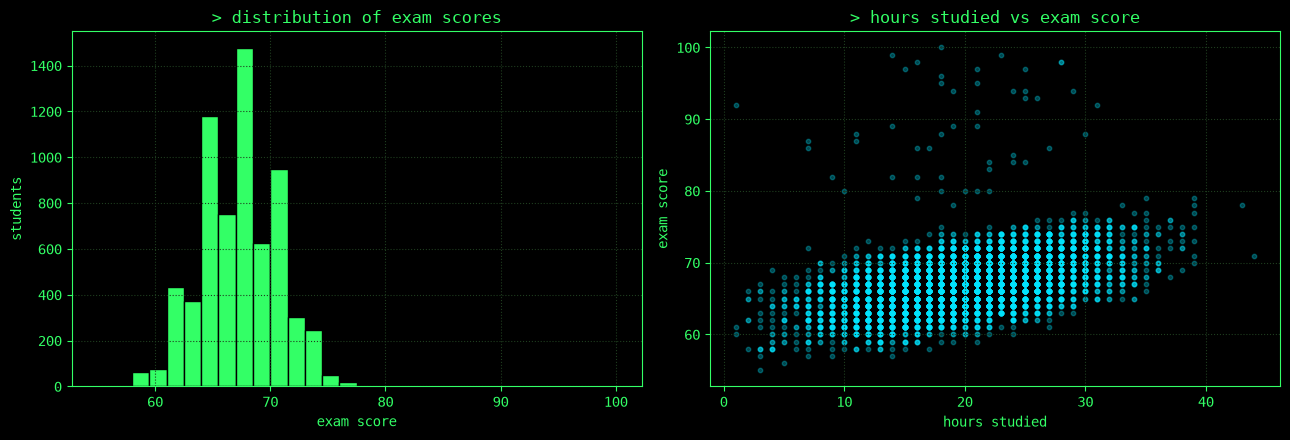

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(df['Exam_Score'], bins=30, color=GREEN, edgecolor='black')
axes[0].set(title='> distribution of exam scores', xlabel='exam score', ylabel='students')

axes[1].scatter(df['Hours_Studied'], df['Exam_Score'], alpha=0.3, s=10, color=CYAN)
axes[1].set(title='> hours studied vs exam score', xlabel='hours studied', ylabel='exam score')

plt.tight_layout()
plt.show()

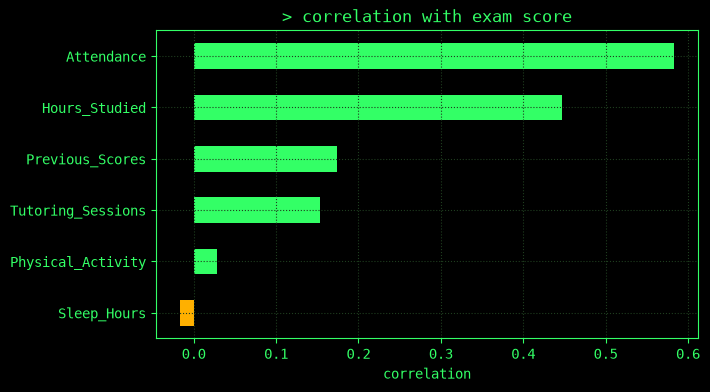

> CORRELATION WITH EXAM SCORE      
┌───────────────────┬─────────────┐
│                   │ correlation │
├───────────────────┼─────────────┤
│ Attendance        │       0.582 │
│ Hours_Studied     │       0.447 │
│ Previous_Scores   │       0.174 │
│ Tutoring_Sessions │       0.154 │
│ Physical_Activity │       0.028 │
│ Sleep_Hours       │      -0.016 │
└───────────────────┴─────────────┘

In [9]:
# Which numeric factors move together with the exam score?
corr = df.select_dtypes('number').corr()['Exam_Score'].drop('Exam_Score').sort_values()
corr.plot(kind='barh', figsize=(7, 4), color=[AMBER if v < 0 else GREEN for v in corr], title='> correlation with exam score')
plt.xlabel('correlation')
plt.show()
term_table(corr.sort_values(ascending=False).to_frame('correlation'), 'CORRELATION WITH EXAM SCORE')

## 4. Train / test split
80% of students are used to train the model, 20% are held back to test it on data it has never seen.

In [10]:
X = df[['Hours_Studied']]
y = df['Exam_Score']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
term_panel('TRAIN / TEST SPLIT', [f'train : {len(X_train):,} students (80%)', f'test  : {len(X_test):,} students (20%)'])

┌─ TRAIN / TEST SPLIT ───────────┐
│ $ train : 5,284 students (80%) │
│ $ test  : 1,322 students (20%) │
└────────────────────────────────┘

## 5. Linear regression

In [11]:
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

term_panel('MODEL TRAINED', [f'Exam_Score = {model.intercept_:.2f} + {model.coef_[0]:.3f} x Hours_Studied'])

┌─ MODEL TRAINED ──────────────────────────────┐
│ $ Exam_Score = 61.55 + 0.286 x Hours_Studied │
└──────────────────────────────────────────────┘

In [12]:
def evaluate(y_true, y_pred):
    return {
        'MAE': mean_absolute_error(y_true, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_true, y_pred)),
        'R2': r2_score(y_true, y_pred),
    }

linear_scores = evaluate(y_test, y_pred)
term_panel('EVALUATION (TEST SET)', [f'{name:<4} : {value:.3f}' for name, value in linear_scores.items()])

┌─ EVALUATION (TEST SET) ─┐
│ $ MAE  : 2.419          │
│ $ RMSE : 3.156          │
│ $ R2   : 0.247          │
└─────────────────────────┘

## 6. Visualize predictions

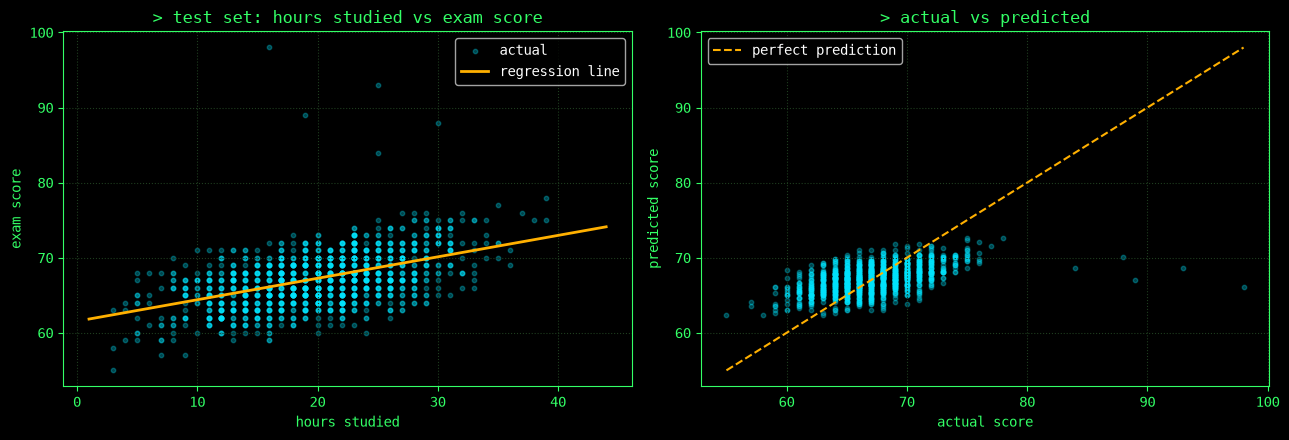

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

line_x = pd.DataFrame({'Hours_Studied': np.linspace(X['Hours_Studied'].min(), X['Hours_Studied'].max(), 100)})
axes[0].scatter(X_test, y_test, alpha=0.3, s=10, color=CYAN, label='actual')
axes[0].plot(line_x, model.predict(line_x), color=AMBER, linewidth=2, label='regression line')
axes[0].set(title='> test set: hours studied vs exam score', xlabel='hours studied', ylabel='exam score')
axes[0].legend()

axes[1].scatter(y_test, y_pred, alpha=0.3, s=10, color=CYAN)
lims = [y_test.min(), y_test.max()]
axes[1].plot(lims, lims, color=AMBER, linestyle='--', label='perfect prediction')
axes[1].set(title='> actual vs predicted', xlabel='actual score', ylabel='predicted score')
axes[1].legend()

plt.tight_layout()
plt.show()

## 7. Bonus: polynomial regression
Does a curved line fit study hours better than a straight one?

In [14]:
results = {'Linear (degree 1)': linear_scores}
for degree in [2, 3]:
    poly = make_pipeline(PolynomialFeatures(degree), LinearRegression())
    poly.fit(X_train, y_train)
    results[f'Polynomial (degree {degree})'] = evaluate(y_test, poly.predict(X_test))

term_table(pd.DataFrame(results).T, 'LINEAR VS POLYNOMIAL')

> LINEAR VS POLYNOMIAL                           
┌───────────────────────┬───────┬───────┬───────┐
│                       │   MAE │  RMSE │    R2 │
├───────────────────────┼───────┼───────┼───────┤
│ Linear (degree 1)     │ 2.419 │ 3.156 │ 0.247 │
│ Polynomial (degree 2) │ 2.415 │ 3.154 │ 0.248 │
│ Polynomial (degree 3) │ 2.417 │ 3.158 │ 0.246 │
└───────────────────────┴───────┴───────┴───────┘

## 8. Bonus: different feature combinations
Study hours alone only explain part of the score. Adding more factors should help.

In [15]:
feature_sets = {
    'Hours only': ['Hours_Studied'],
    'Hours + Attendance': ['Hours_Studied', 'Attendance'],
    'Hours + Attendance + Sleep': ['Hours_Studied', 'Attendance', 'Sleep_Hours'],
    'Hours + Attendance + Previous Scores': ['Hours_Studied', 'Attendance', 'Previous_Scores'],
    'All features': [c for c in df.columns if c != 'Exam_Score'],
}

# One-hot encode the text columns so the model can use them
df_encoded = pd.get_dummies(df, drop_first=True)

combo_results = {}
for name, cols in feature_sets.items():
    encoded_cols = [c for c in df_encoded.columns if any(c == col or c.startswith(col + '_') for col in cols)]
    Xf = df_encoded[encoded_cols]
    Xf_train, Xf_test, yf_train, yf_test = train_test_split(Xf, y, test_size=0.2, random_state=42)
    m = LinearRegression().fit(Xf_train, yf_train)
    combo_results[name] = evaluate(yf_test, m.predict(Xf_test))

combo_df = pd.DataFrame(combo_results).T
term_table(combo_df, 'FEATURE COMBINATIONS')

> FEATURE COMBINATIONS                                          
┌──────────────────────────────────────┬───────┬───────┬───────┐
│                                      │   MAE │  RMSE │    R2 │
├──────────────────────────────────────┼───────┼───────┼───────┤
│ Hours only                           │ 2.419 │ 3.156 │ 0.247 │
│ Hours + Attendance                   │ 1.430 │ 2.237 │ 0.622 │
│ Hours + Attendance + Sleep           │ 1.429 │ 2.236 │ 0.622 │
│ Hours + Attendance + Previous Scores │ 1.330 │ 2.135 │ 0.655 │
│ All features                         │ 0.416 │ 1.521 │ 0.825 │
└──────────────────────────────────────┴───────┴───────┴───────┘

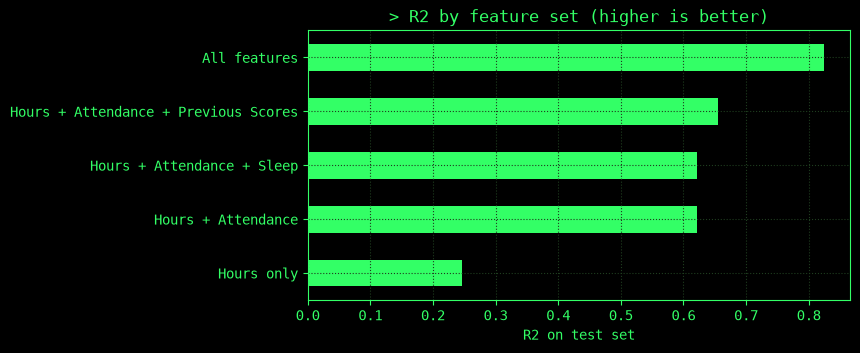

In [16]:
combo_df['R2'].plot(kind='barh', figsize=(7, 3.5), color=GREEN, title='> R2 by feature set (higher is better)')
plt.xlabel('R2 on test set')
plt.show()

## 9. Conclusions

- **Data cleaning:** 6,607 students. 235 missing values in three text columns (Teacher_Quality, Parental_Education_Level, Distance_from_Home) were filled with the most common value, and 1 impossible score above 100 was removed, leaving 6,606 rows.
- **Linear regression on study hours:** `Exam_Score = 61.55 + 0.286 x Hours_Studied`, so each extra hour of study adds about 0.29 points. On the test set: MAE 2.42, RMSE 3.16, **R2 0.247**. Study hours alone explain about a quarter of the variation in scores.
- **Polynomial regression (bonus):** degree 2 and 3 scored almost the same as the straight line (R2 0.248 and 0.246). The relationship is linear, so a curve adds nothing.
- **Feature combinations (bonus):** adding Attendance raises R2 to 0.622, and Attendance is the single strongest factor (correlation 0.58, versus 0.45 for study hours). Sleep hours add nothing (correlation -0.02). Using all features reaches **R2 0.825** with an average error of only 0.42 points.
- **Takeaway:** studying more helps, but showing up to class matters even more, and a student's score depends on many factors together.